# =========================================================
# 2) INDICATORS (Strategy_1_34_192)
#   - Dual Keltner: period=20 dev=1.5 & 2.0 (Typical Price + ATR20)
#   - RSI(14) on Close (Wilder EMA)
#   - Highest/Lowest Close (10) for breakout anchor (shift=3)
#   - ATR23 (shift=3) for entry buffer
#   - ATR20 (shift=1) SL, ATR25 (shift=1) TP, ATR150 (shift=1) Trailing
# =========================================================

⏳ Đang tải dữ liệu ETHUSDT khung 1h...
✅ Data ready: 17592 bars. Calculating indicators...
🚀 Running Strategy_1_34_192 backtest...

🎯 STRATEGY - Strategy_1_34_192 (Dual KC + RSI slope + Stop Orders)
     Final Equity: 13718.9725
     Total Return: 0.3719
    CAGR (approx): 0.1724
     Max Drawdown: -0.1118
           Sharpe: 1.2707
           Trades: 331
          Winrate: 0.4713
    Avg PnL/Trade: 11.2356
    Profit Factor: 1.2269


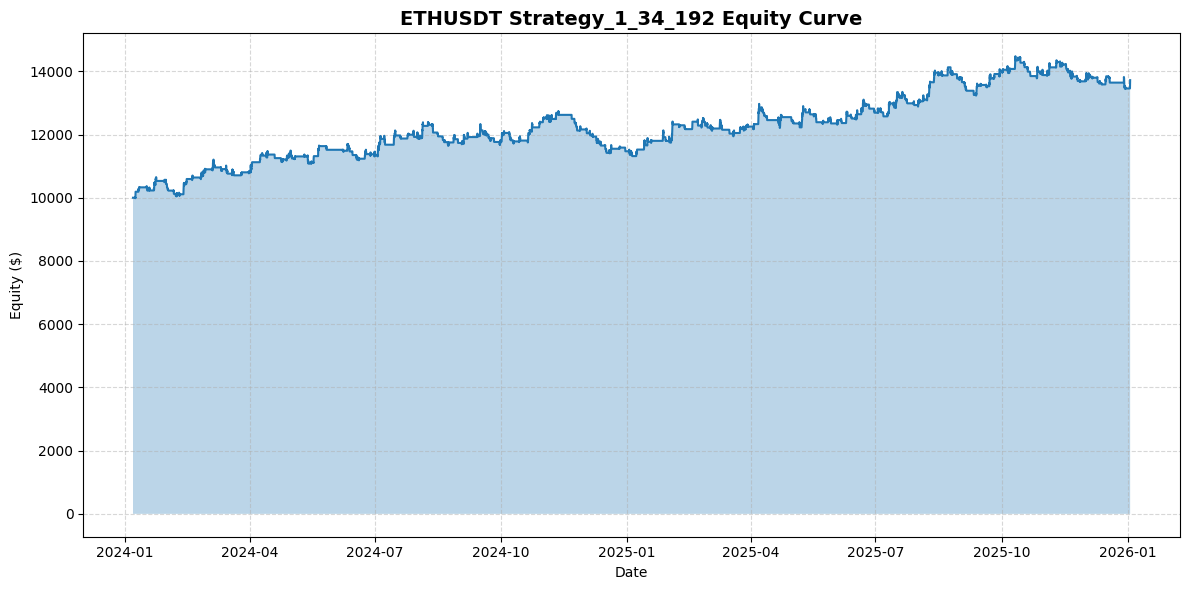


📊 Sample Trades:
            Exit Time   Type        Entry         Exit   Qty         PnL              Reason       Balance
0 2024-01-08 19:00:00   LONG  2267.270320  2342.880721  2.51  189.782105         Take Profit  10189.782105
1 2024-01-11 12:00:00   LONG  2531.476114  2647.020000  1.20  138.652664           Time Exit  10328.434769
2 2024-01-17 08:00:00   LONG  2590.557696  2546.572081  2.34 -102.926340  Stop Loss/Trailing  10225.508428
3 2024-01-19 08:00:00  SHORT  2475.137617  2473.500000  2.76    4.519822           Time Exit  10230.028250
4 2024-01-22 09:00:00  SHORT  2433.416738  2386.022804  4.31  204.267854         Take Profit  10434.296104
5 2024-01-22 19:00:00  SHORT  2381.350000  2375.402998  3.35   19.922458  Stop Loss/Trailing  10454.218562
6 2024-01-23 09:00:00  SHORT  2324.513670  2272.103418  2.24  117.398964  Stop Loss/Trailing  10571.617526
7 2024-01-23 23:00:00  SHORT  2223.350000  2243.043444  2.06  -40.568495  Stop Loss/Trailing  10531.049030
8 2024-01-30 08:00:

In [2]:
import requests
import pandas as pd
import numpy as np
from datetime import datetime
import time
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# =========================================================
# 1) HÀM TẢI DỮ LIỆU BINANCE (SPOT) - GIỮ NGUYÊN
# =========================================================
def str_to_millis(date_str: str) -> int:
    dt = datetime.strptime(date_str, "%d/%m/%Y")
    return int(dt.timestamp() * 1000)

def fetch_binance_kline_df(symbol: str, interval: str, start_str: str, end_str: str) -> pd.DataFrame:
    base_url = "https://api.binance.com/"
    api_url = "api/v3/klines"
    general_url = base_url + api_url

    start_time = str_to_millis(start_str)
    end_dt = datetime.strptime(end_str, "%d/%m/%Y").replace(hour=23, minute=59, second=59)
    end_time = int(end_dt.timestamp() * 1000)

    all_klines = []
    print(f"⏳ Đang tải dữ liệu {symbol} khung {interval}...")

    while start_time < end_time:
        params = {
            "symbol": symbol.upper(),
            "interval": interval,
            "startTime": start_time,
            "endTime": end_time,
            "limit": 1000
        }
        try:
            response = requests.get(general_url, params=params, timeout=10)
            if response.status_code != 200:
                print("Error:", response.status_code, response.text)
                break
            data = response.json()
            if not data:
                break
            all_klines.extend(data)
            last_ts = data[-1][0]
            start_time = last_ts + 1
            time.sleep(0.05)
        except Exception as e:
            print(f"Lỗi: {e}")
            break

    if not all_klines:
        return pd.DataFrame()

    df = pd.DataFrame(all_klines, columns=[
        "timestamp", "Open", "High", "Low", "Close", "Volume",
        "close_time", "quote_asset_volume", "num_trades",
        "taker_buy_base_volume", "taker_buy_quote_volume", "ignore"
    ])
    df = df[["timestamp", "Open", "High", "Low", "Close", "Volume"]]
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")
    df.set_index("timestamp", inplace=True)
    df = df.astype(float)
    return df


# =========================================================
# 2) INDICATORS (Strategy_1_34_192)
#   - Dual Keltner: period=20 dev=1.5 & 2.0 (Typical Price + ATR20)
#   - RSI(14) on Close (Wilder EMA)
#   - Highest/Lowest Close (10) for breakout anchor (shift=3)
#   - ATR23 (shift=3) for entry buffer
#   - ATR20 (shift=1) SL, ATR25 (shift=1) TP, ATR150 (shift=1) Trailing
# =========================================================
def _true_range(df: pd.DataFrame) -> pd.Series:
    prev_close = df["Close"].shift(1)
    tr = pd.concat(
        [
            (df["High"] - df["Low"]),
            (df["High"] - prev_close).abs(),
            (df["Low"] - prev_close).abs(),
        ],
        axis=1,
    ).max(axis=1)
    return tr

def _atr_wilder(tr: pd.Series, period: int) -> pd.Series:
    return tr.ewm(alpha=1/period, min_periods=period, adjust=False).mean()

def _rsi_wilder(close: pd.Series, period: int) -> pd.Series:
    delta = close.diff()
    gain = delta.clip(lower=0.0)
    loss = (-delta).clip(lower=0.0)
    avg_gain = gain.ewm(alpha=1/period, min_periods=period, adjust=False).mean()
    avg_loss = loss.ewm(alpha=1/period, min_periods=period, adjust=False).mean()
    rs = avg_gain / avg_loss
    return 100 - (100 / (1 + rs))

def calculate_indicators_strategy_1_34_192(df: pd.DataFrame) -> pd.DataFrame:
    data = df.copy()

    # Typical Price
    data["Typical"] = (data["High"] + data["Low"] + data["Close"]) / 3.0

    # TR + ATRs
    data["TR"] = _true_range(data)
    data["ATR_20"]  = _atr_wilder(data["TR"], 20)
    data["ATR_23"]  = _atr_wilder(data["TR"], 23)
    data["ATR_25"]  = _atr_wilder(data["TR"], 25)
    data["ATR_150"] = _atr_wilder(data["TR"], 150)

    # KC center EMA(20) on Typical
    data["EMA_20_typ"] = data["Typical"].ewm(span=20, adjust=False).mean()

    # Dual Keltner devs (1.5 & 2.0)
    data["KC_U_20_15"] = data["EMA_20_typ"] + 1.5 * data["ATR_20"]
    data["KC_L_20_15"] = data["EMA_20_typ"] - 1.5 * data["ATR_20"]
    data["KC_U_20_20"] = data["EMA_20_typ"] + 2.0 * data["ATR_20"]
    data["KC_L_20_20"] = data["EMA_20_typ"] - 2.0 * data["ATR_20"]

    # RSI(14) on Close
    data["RSI_14"] = _rsi_wilder(data["Close"], 14)

    # Breakout anchors on Close (lookback 10)
    data["HH_Close_10"] = data["Close"].rolling(window=10).max()
    data["LL_Close_10"] = data["Close"].rolling(window=10).min()

    data.dropna(inplace=True)
    return data


# =========================================================
# 3) BACKTESTER (format giống mẫu DualKCRSIBacktester)
# =========================================================
class Strategy134192Backtester:
    def __init__(self, df: pd.DataFrame, initial_balance: float = 10000.0):
        self.df = df
        self.initial_balance = float(initial_balance)
        self.balance = float(initial_balance)

        self.equity_curve = []
        self.trades = []

        self.position = None          # None / 'LONG' / 'SHORT'
        self.entry_price = 0.0
        self.sl = 0.0
        self.tp = 0.0
        self.entry_bar_idx = 0
        self.qty = 0.0

        self.pending_order = None     # {'type','price','sl_dist','tp_dist','trail_dist','expire_idx'}
        self.trailing_sl = None
        self.trailing_dist = None

        # ===== Strategy Params (Strategy_1_34_192) =====
        self.risk_pct = 0.01
        self.price_entry_mult = 2.4
        self.pending_expiration = 5
        self.sl_coef = 2.2
        self.tp_coef = 4.3
        self.trailing_coef = 3.0
        self.exit_after_bars = 14

        # (optional) cap giống SQ template
        self.mm_max_lots = 100.0
        self.mm_decimals = 2

    def run(self):
        indices = self.df.index

        for i in range(len(self.df)):
            current_bar = self.df.iloc[i]
            idx = indices[i]

            # -------------------------------------------------
            # A) MANAGE OPEN POSITION (Trailing + SL/TP + Time Exit)
            # -------------------------------------------------
            if self.position is not None:
                bars_held = i - self.entry_bar_idx

                # Time exit
                if bars_held >= self.exit_after_bars:
                    self.close_position(current_bar["Close"], idx, "Time Exit")
                    self.append_equity(idx)
                    continue

                # Update trailing (range, bar-based)
                if self.trailing_dist is not None:
                    if self.position == "LONG":
                        new_trailing = float(current_bar["Close"]) - float(self.trailing_dist)
                        if self.trailing_sl is None or new_trailing > self.trailing_sl:
                            self.trailing_sl = new_trailing
                            self.sl = max(self.sl, self.trailing_sl)
                    else:
                        new_trailing = float(current_bar["Close"]) + float(self.trailing_dist)
                        if self.trailing_sl is None or new_trailing < self.trailing_sl:
                            self.trailing_sl = new_trailing
                            self.sl = min(self.sl, self.trailing_sl)

                # Intrabar exits (SL before TP)
                if self.position == "LONG":
                    if current_bar["Low"] <= self.sl:
                        self.close_position(self.sl, idx, "Stop Loss/Trailing")
                        self.append_equity(idx)
                        continue
                    if current_bar["High"] >= self.tp:
                        self.close_position(self.tp, idx, "Take Profit")
                        self.append_equity(idx)
                        continue
                else:  # SHORT
                    if current_bar["High"] >= self.sl:
                        self.close_position(self.sl, idx, "Stop Loss/Trailing")
                        self.append_equity(idx)
                        continue
                    if current_bar["Low"] <= self.tp:
                        self.close_position(self.tp, idx, "Take Profit")
                        self.append_equity(idx)
                        continue

            # -------------------------------------------------
            # B) MANAGE PENDING ORDER (expiration + fill)
            # -------------------------------------------------
            if self.position is None and self.pending_order is not None:
                if i >= self.pending_order["expire_idx"]:
                    self.pending_order = None
                else:
                    p_price = float(self.pending_order["price"])

                    # BUY STOP fill
                    if self.pending_order["type"] == "BUY_STOP" and current_bar["High"] >= p_price:
                        fill_price = max(p_price, float(current_bar["Open"]))  # gap model
                        self.open_position(
                            "LONG", fill_price, i,
                            self.pending_order["sl_dist"],
                            self.pending_order["tp_dist"],
                            self.pending_order["trail_dist"],
                        )
                        self.pending_order = None

                    # SELL STOP fill
                    elif self.pending_order["type"] == "SELL_STOP" and current_bar["Low"] <= p_price:
                        fill_price = min(p_price, float(current_bar["Open"]))  # gap model
                        self.open_position(
                            "SHORT", fill_price, i,
                            self.pending_order["sl_dist"],
                            self.pending_order["tp_dist"],
                            self.pending_order["trail_dist"],
                        )
                        self.pending_order = None

            # -------------------------------------------------
            # C) SIGNAL → CREATE PENDING (đúng shift + rule)
            # -------------------------------------------------
            if self.position is None and self.pending_order is None:
                # cần i>=3 để dùng RSI shift=3 vs shift=2, và i>=3 để HH/LL shift=3, ATR23 shift=3
                if i < 3:
                    self.append_equity(idx)
                    continue

                open0 = float(current_bar["Open"])

                # KC shift=1 => i-1, nên cần i>=1 (đã ok)
                kc_u_15_1 = float(self.df.iloc[i-1]["KC_U_20_15"])
                kc_l_15_1 = float(self.df.iloc[i-1]["KC_L_20_15"])
                kc_u_20_1 = float(self.df.iloc[i-1]["KC_U_20_20"])
                kc_l_20_1 = float(self.df.iloc[i-1]["KC_L_20_20"])

                # RSI slope: RSI[3] vs RSI[2] => i-3 vs i-2
                if i < 3:
                    self.append_equity(idx)
                    continue
                rsi_3 = float(self.df.iloc[i-3]["RSI_14"])
                rsi_2 = float(self.df.iloc[i-2]["RSI_14"])

                long_signal = (open0 > kc_u_15_1) and (open0 > kc_u_20_1) and (rsi_3 < rsi_2)
                short_signal = (open0 < kc_l_15_1) and (open0 < kc_l_20_1) and (rsi_3 > rsi_2)

                if (not long_signal) and (not short_signal):
                    self.append_equity(idx)
                    continue

                # Anchors shift=3 (i-3)
                hh_10_3 = float(self.df.iloc[i-3]["HH_Close_10"])
                ll_10_3 = float(self.df.iloc[i-3]["LL_Close_10"])

                # ATR23 shift=3 (i-3)
                atr23_3 = float(self.df.iloc[i-3]["ATR_23"])

                # SL/TP dist shift=1 (i-1)
                atr20_1 = float(self.df.iloc[i-1]["ATR_20"])
                atr25_1 = float(self.df.iloc[i-1]["ATR_25"])
                sl_dist = self.sl_coef * atr20_1
                tp_dist = self.tp_coef * atr25_1

                # Trailing dist shift=1 (i-1)
                atr150_1 = float(self.df.iloc[i-1]["ATR_150"])
                trail_dist = self.trailing_coef * atr150_1

                expire_idx = int(i + self.pending_expiration)

                # LONG ưu tiên
                if long_signal:
                    entry_price = hh_10_3 + (self.price_entry_mult * atr23_3)
                    self.pending_order = {
                        "type": "BUY_STOP",
                        "price": float(entry_price),
                        "sl_dist": float(sl_dist),
                        "tp_dist": float(tp_dist),
                        "trail_dist": float(trail_dist),
                        "expire_idx": expire_idx,
                    }
                elif short_signal and (not long_signal):
                    entry_price = ll_10_3 - (self.price_entry_mult * atr23_3)
                    self.pending_order = {
                        "type": "SELL_STOP",
                        "price": float(entry_price),
                        "sl_dist": float(sl_dist),
                        "tp_dist": float(tp_dist),
                        "trail_dist": float(trail_dist),
                        "expire_idx": expire_idx,
                    }

            # -------------------------------------------------
            # D) APPEND EQUITY (MARK-TO-MARKET)
            # -------------------------------------------------
            self.append_equity(idx)

    def append_equity(self, idx):
        mark_to_market = self.balance
        close_price = float(self.df.loc[idx, "Close"])

        if self.position == "LONG":
            mark_to_market += (close_price - self.entry_price) * self.qty
        elif self.position == "SHORT":
            mark_to_market += (self.entry_price - close_price) * self.qty

        self.equity_curve.append({"time": idx, "equity": mark_to_market})

    def open_position(self, pos_type: str, price: float, bar_idx: int,
                      sl_dist: float, tp_dist: float, trail_dist: float):
        self.position = pos_type
        self.entry_price = float(price)
        self.entry_bar_idx = int(bar_idx)

        if pos_type == "LONG":
            self.sl = self.entry_price - float(sl_dist)
            self.tp = self.entry_price + float(tp_dist)
        else:
            self.sl = self.entry_price + float(sl_dist)
            self.tp = self.entry_price - float(tp_dist)

        # trailing config (fixed distance per trade)
        self.trailing_dist = float(trail_dist)
        self.trailing_sl = None

        # Risk sizing
        risk_amount = self.balance * self.risk_pct
        sl_distance = abs(self.entry_price - self.sl)
        qty = (risk_amount / sl_distance) if sl_distance > 0 else 0.0

        # clamp + rounding down
        qty = min(qty, self.mm_max_lots)
        scale = 10 ** self.mm_decimals
        qty = np.floor(qty * scale) / scale
        self.qty = float(qty)

    def close_position(self, price: float, time_idx, reason: str):
        price = float(price)

        if self.position == "LONG":
            pnl = (price - self.entry_price) * self.qty
        else:
            pnl = (self.entry_price - price) * self.qty

        self.balance += pnl

        self.trades.append({
            "Exit Time": time_idx,
            "Type": self.position,
            "Entry": self.entry_price,
            "Exit": price,
            "Qty": self.qty,
            "PnL": pnl,
            "Reason": reason,
            "Balance": self.balance
        })

        self.position = None
        self.qty = 0.0
        self.trailing_sl = None
        self.trailing_dist = None


# =========================================================
# 4) METRICS + PLOT
# =========================================================
def calculate_metrics(trades_df: pd.DataFrame, equity_data, initial_balance: float):
    eq_df = pd.DataFrame(equity_data).set_index("time")
    eq_df = eq_df[~eq_df.index.duplicated(keep="last")]

    final_equity = float(eq_df["equity"].iloc[-1])
    total_return = (final_equity - initial_balance) / initial_balance

    days = (eq_df.index[-1] - eq_df.index[0]).days
    years = days / 365.25 if days > 0 else 0.0
    cagr = ((final_equity / initial_balance) ** (1/years) - 1) if years > 0 else 0.0

    running_max = eq_df["equity"].cummax()
    drawdown = (eq_df["equity"] - running_max) / running_max
    max_dd = float(drawdown.min())

    eq_df["returns"] = eq_df["equity"].pct_change()
    mean_ret = float(eq_df["returns"].mean())
    std_ret = float(eq_df["returns"].std())

    bars_per_year = (len(eq_df) / years) if years > 0 else 8760
    sharpe = (mean_ret / std_ret) * np.sqrt(bars_per_year) if std_ret != 0 else 0.0

    total_trades = len(trades_df)
    win_trades = len(trades_df[trades_df["PnL"] > 0])
    win_rate = (win_trades / total_trades) if total_trades > 0 else 0.0
    avg_pnl = float(trades_df["PnL"].mean()) if total_trades > 0 else 0.0

    gross_profit = float(trades_df[trades_df["PnL"] > 0]["PnL"].sum())
    gross_loss = float(abs(trades_df[trades_df["PnL"] < 0]["PnL"].sum()))
    profit_factor = (gross_profit / gross_loss) if gross_loss > 0 else 0.0

    return {
        "Final Equity": final_equity,
        "Total Return": total_return,
        "CAGR (approx)": cagr,
        "Max Drawdown": max_dd,
        "Sharpe": sharpe,
        "Trades": total_trades,
        "Winrate": win_rate,
        "Avg PnL/Trade": avg_pnl,
        "Profit Factor": profit_factor,
        "equity_df": eq_df
    }

def print_report_and_plot(metrics, symbol: str):
    print("\n" + "="*60)
    print("🎯 STRATEGY - Strategy_1_34_192 (Dual KC + RSI slope + Stop Orders)")
    print("="*60)
    print(f"     Final Equity: {metrics['Final Equity']:.4f}")
    print(f"     Total Return: {metrics['Total Return']:.4f}")
    print(f"    CAGR (approx): {metrics['CAGR (approx)']:.4f}")
    print(f"     Max Drawdown: {metrics['Max Drawdown']:.4f}")
    print(f"           Sharpe: {metrics['Sharpe']:.4f}")
    print(f"           Trades: {metrics['Trades']}")
    print(f"          Winrate: {metrics['Winrate']:.4f}")
    print(f"    Avg PnL/Trade: {metrics['Avg PnL/Trade']:.4f}")
    print(f"    Profit Factor: {metrics['Profit Factor']:.4f}")
    print("="*60)

    eq_df = metrics["equity_df"]
    plt.figure(figsize=(12, 6))
    plt.plot(eq_df.index, eq_df["equity"], linewidth=1.5)
    plt.fill_between(eq_df.index, eq_df["equity"], alpha=0.3)

    plt.title(f"{symbol} Strategy_1_34_192 Equity Curve", fontsize=14, fontweight="bold")
    plt.xlabel("Date")
    plt.ylabel("Equity ($)")
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()


# =========================================================
# 5) MAIN (FULL PIPELINE)
# =========================================================
if __name__ == "__main__":
    symbol = "ETHUSDT"
    interval = "1h"
    start_date = "01/01/2024"
    end_date = "02/01/2026"

    # 1) Fetch SPOT data (giữ nguyên hàm của bạn)
    df_raw = fetch_binance_kline_df(symbol, interval, start_date, end_date)

    if len(df_raw) > 300:
        print(f"✅ Data ready: {len(df_raw)} bars. Calculating indicators...")
        df_calc = calculate_indicators_strategy_1_34_192(df_raw)

        print("🚀 Running Strategy_1_34_192 backtest...")
        bt = Strategy134192Backtester(df_calc, initial_balance=10000.0)
        bt.run()

        trades_df = pd.DataFrame(bt.trades)

        if not trades_df.empty:
            metrics = calculate_metrics(trades_df, bt.equity_curve, bt.initial_balance)
            print_report_and_plot(metrics, symbol)

            print("\n📊 Sample Trades:")
            print(trades_df.head(10).to_string())

            print("\n📈 Exit Reasons:")
            print(trades_df["Reason"].value_counts())
        else:
            print("⚠️ No trades.")
    else:
        print("❌ Insufficient data.")
